# Generative Modelling I — from randomness to data

ES667 · Nipun Batra · companion to the 80-minute lecture.

**OBSERVED DATA** is thresholded MNIST. **MEASURED** panels come from the saved local training run. **ILLUSTRATIVE** diagrams and **ANALYTICAL / EXACT** calculations are separate.

The notebook runs offline with the included checkpoints and recordings. Set `RUN_TRAINING=True` to repeat training (first run downloads MNIST). This small instructional run is not a benchmark.


In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import torch
from IPython.display import display, Image, SVG
ROOT = Path.cwd()
if not (ROOT / 'metrics').exists():
    ROOT = ROOT.parent
assert (ROOT / 'metrics/mnist.json').exists(), 'Run from the project or notebooks directory.'
sys.path.insert(0, str(ROOT / 'experiments'))
from train_mnist import Model
metrics = json.loads((ROOT / 'metrics/mnist.json').read_text())
print('Saved run:', metrics['train_examples'], 'training examples;', metrics['epochs'], 'epochs; seed', metrics['seed'])
print('Preprocessing:', metrics['preprocessing'])


Saved run: 60000 training examples; 15 epochs; seed 667
Preprocessing: fixed binary threshold uint8 > 127


## Reproduce the run

The script trains AE-2, VAE-2 and VAE-16 using the same binary data. It saves weights, train curves, fixed held-out reconstructions, prior draws, decoder means and latent recordings. It never uses test digits during optimization.


In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT / 'experiments/train_mnist.py'), '--epochs', '15', '--seed', '667'], check=True)
else:
    print('Using the included measured run. No training is claimed for this notebook execution.')


Using the included measured run. No training is claimed for this notebook execution.


## One random draw, a differentiable path

With $\mu=2$, $\sigma=.5$, $\epsilon=-.8$, calculate $z$. Then suppose the upstream reconstruction gradient is 3. These are reconstruction-path derivatives only; the KL term supplies additional derivatives in the complete VAE.


In [3]:
mu = torch.tensor(2., requires_grad=True)
sigma = torch.tensor(.5, requires_grad=True)
eps = torch.tensor(-.8)
z = mu + sigma * eps
(3*z).backward()
print('z:', z.item(), 'dL/dmu:', mu.grad.item(), 'dL/dsigma:', sigma.grad.item())
q = torch.distributions.Normal(1., .5)
p = torch.distributions.Normal(0., 1.)
print('KL in nats:', torch.distributions.kl_divergence(q, p).item())


z: 1.600000023841858 dL/dmu: 3.0 dL/dsigma: -2.4000000953674316
KL in nats: 0.8181471824645996


## Load the actual decoder

The network produces Bernoulli logits. Sigmoid gives a mean image; sampling Bernoulli observations gives an actual binary draw. These are different displays.


Shape: (28, 28) mean probability: 0.13836999237537384


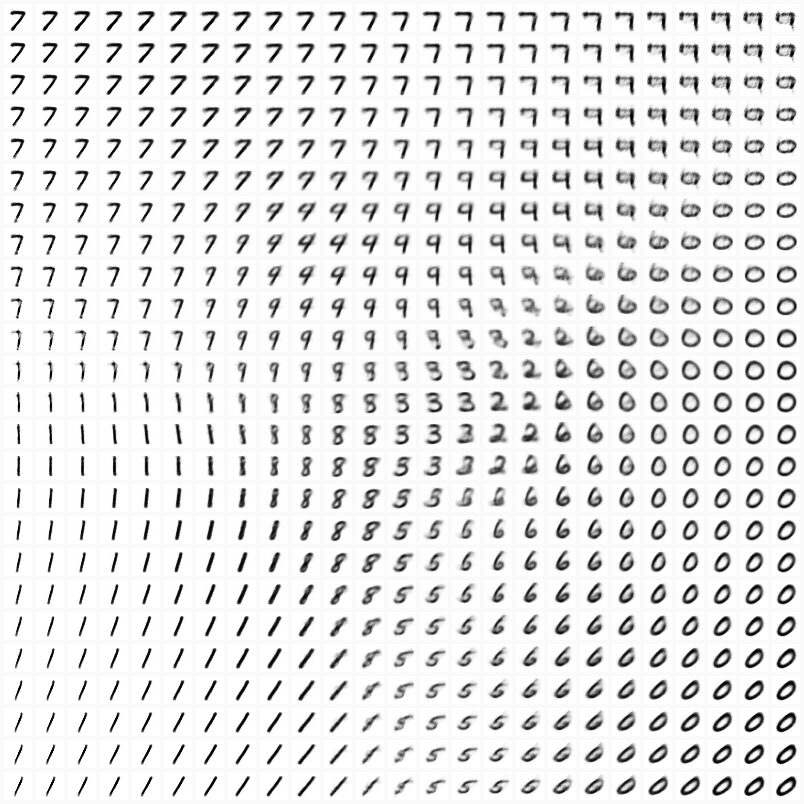

In [4]:
checkpoint = torch.load(ROOT / 'models/vae2.pt', map_location='cpu', weights_only=True)
model = Model(checkpoint['latent_dim'], vae=True)
model.load_state_dict(checkpoint['state_dict'])
model.eval()
z = torch.tensor([[0., 0.]])
with torch.no_grad():
    mean_image = model.dec(z).sigmoid().reshape(28,28)
print('Shape:', tuple(mean_image.shape), 'mean probability:', mean_image.mean().item())
display(Image(filename=str(ROOT / 'figures/vae2-grid.png'), width=520))


## Inspect held-out reconstructions and prior outputs

Top row: original binary input. Bottom row: decoder mean evaluated at the posterior mean. The prior outputs below are unselected fixed-seed binary draws.


vae2


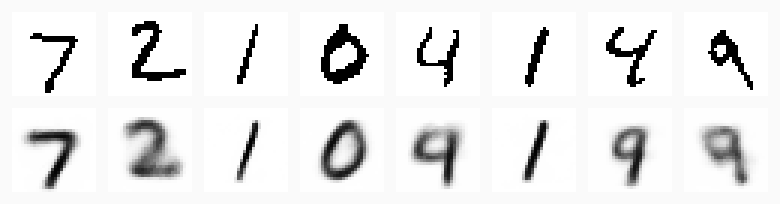

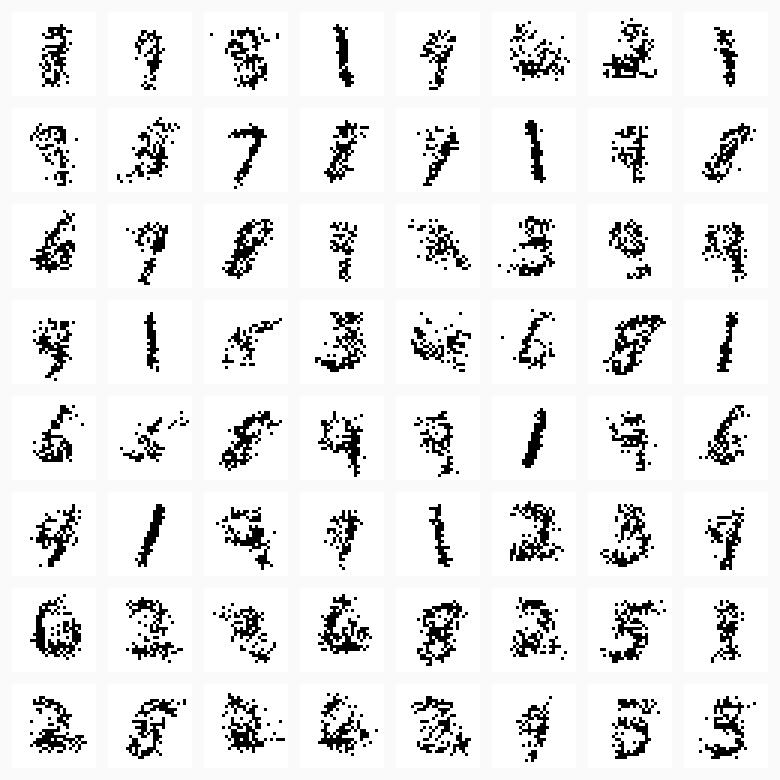

vae16


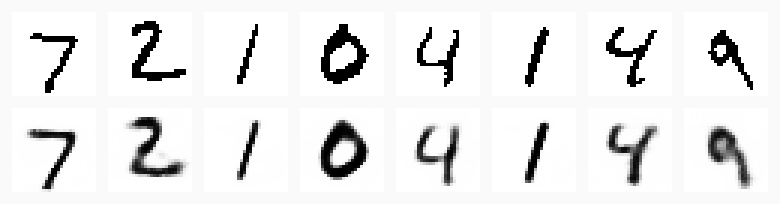

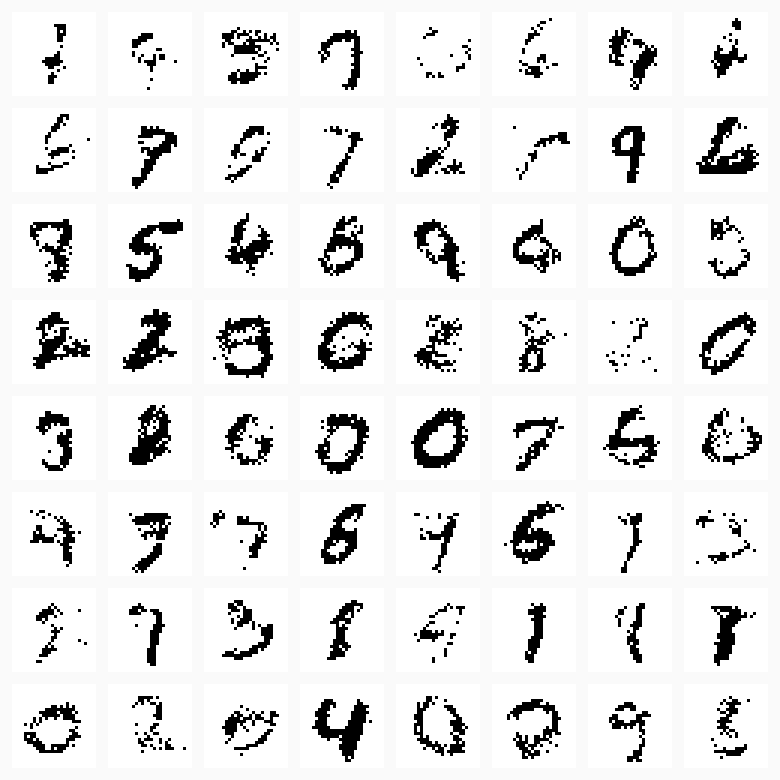

In [5]:
for name in ['vae2', 'vae16']:
    print(name)
    display(Image(filename=str(ROOT / f'figures/{name}-recon.png'), width=760))
    display(Image(filename=str(ROOT / f'figures/{name}-prior-draws.png'), width=360))


## Reproduce interpolation from the saved latent path

The endpoints are the posterior means of the first two test examples. We decode nine equally spaced points. This does not imply that the coordinates have independently interpretable meanings.


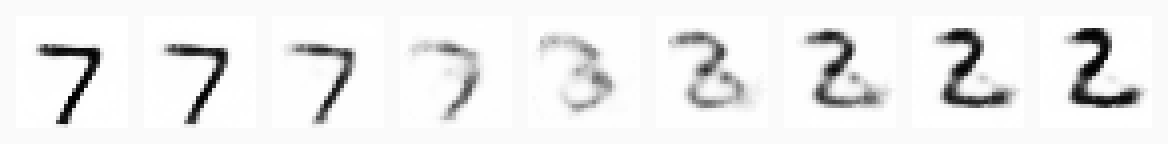

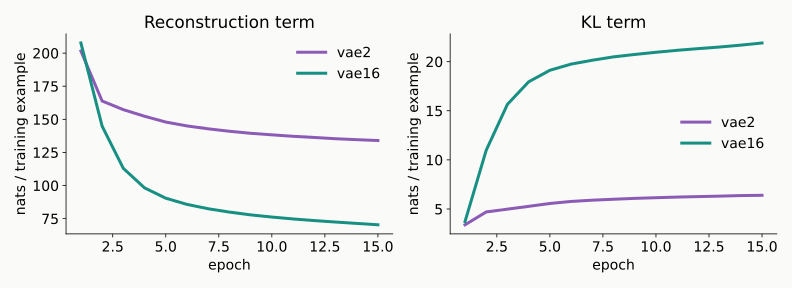

In [6]:
ck = torch.load(ROOT / 'models/vae16.pt', map_location='cpu', weights_only=True)
m16 = Model(16); m16.load_state_dict(ck['state_dict']); m16.eval()
record = np.load(ROOT / 'models/vae16-recording.npz')
path = torch.tensor(record['interpolation_z'])
with torch.no_grad():
    pixels = m16.dec(path).sigmoid()
assert pixels.shape == (9, 784)
display(Image(filename=str(ROOT / 'figures/vae16-interpolation.png'), width=900))
display(SVG(filename=str(ROOT / 'figures/training-curves.svg')))


## Evaluate both terms

Reported VAE test values use one stochastic posterior draw per test example at seed 668. Training curves use per-epoch means. Reconstruction sums 784 binary pixel losses; KL sums latent dimensions. All quantities below are nats per example.


In [7]:
for name, v in metrics['models'].items():
    print(name, {'test_reconstruction': round(v['test_reconstruction_nats'], 3),
                 'test_KL': round(v['test_kl_nats'], 3)})
subprocess.run([sys.executable, str(ROOT / 'experiments/verify_math.py')], check=True, capture_output=True)
print('Analytical, autograd and checkpoint-integrity checks passed.')


ae2 {'test_reconstruction': 133.197, 'test_KL': 0.0}
vae2 {'test_reconstruction': 135.392, 'test_KL': 6.339}
vae16 {'test_reconstruction': 69.963, 'test_KL': 22.023}


Analytical, autograd and checkpoint-integrity checks passed.


## The same two-dimensional distribution

The teaching cloud balances 35 draws per component so every mode stays visible. This is a stratified visualization, not an iid categorical sequence. The separate mixture sampler recipe draws its component at random. Contours use the known analytical density; no trained GAN or flow result is implied.


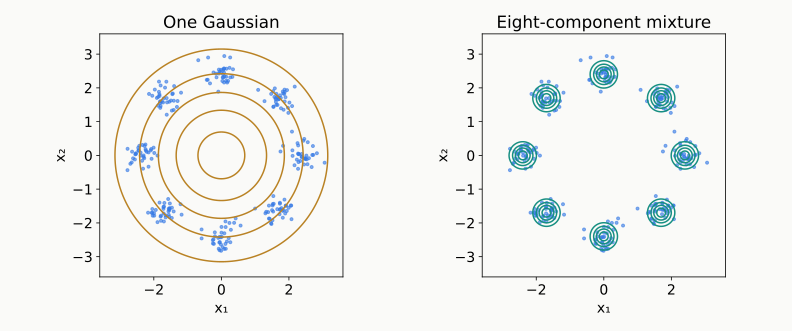

In [8]:
subprocess.run([sys.executable, str(ROOT / 'experiments/distributions.py')], check=True, capture_output=True)
display(SVG(filename=str(ROOT / 'figures/distribution-comparison.svg')))


## Exercises

1. Predict the reconstruction-path derivative with respect to `logvar`; check it with autograd.
2. Change the clicked latent coordinate in the lecture. Explain the difference between a decoder mean and a sampled image.
3. Why does a low AE reconstruction loss not guarantee good standard-prior samples?
4. Freeze discriminator parameters in a tiny network. Check that the generator still gets gradients.
5. Explain why the inverse Jacobian contributes $-\log 2$ for $x=2z$.

## Sources

[Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114) · [GANs](https://arxiv.org/abs/1406.2661) · [Normalizing flows](https://arxiv.org/abs/1505.05770). Full data and image provenance: `SOURCES.md`.


## Rebuild calculations and measured GAN

The shared fixture supplies the slide arithmetic. The GAN snapshots are a separate measured training run on iid draws from the same eight-Gaussian distribution. Coverage alone does not establish that the density matches: inspect the gaps as well.


In [9]:
numbers = json.loads((ROOT/'results/generative_i_teaching_numbers.json').read_text())
for name in ['mle', 'reparam', 'bernoulli', 'kl', 'gan', 'flow']:
    print(name, numbers[name])
subprocess.run([sys.executable, str(ROOT/'experiments/verify_rebuild.py')], check=True, capture_output=True)
print('Fixtures, checkpoint-derived recordings, and bridge frame hashes verified.')


mle {'observations': [-0.5, 0.5, 1.5], 'sigma': 1, 'initial_mu': 0, 'optimal_mu': 0.5, 'initial_log_likelihood': -4.1318155996140185, 'optimal_log_likelihood': -3.756815599614018}
reparam {'mu': 2, 'sigma': 0.5, 'epsilon': -0.8, 'product': -0.4, 'z': 1.6, 'upstream': 3, 'dz_dmu': 1, 'dz_dsigma': -0.8, 'grad_mu': 3, 'grad_sigma': -2.4000000000000004, 'logvar': -1.3862943611198906, 'dz_dlogvar': -0.2, 'grad_logvar': -0.6000000000000001}
bernoulli {'x': [1, 0, 1, 0], 'probabilities': [0.8, 0.3, 0.6, 0.1], 'observed_probabilities': [0.8, 0.7, 0.6, 0.9], 'terms': [0.2231435513142097, 0.35667494393873245, 0.5108256237659907, 0.10536051565782628], 'sum_nats': 1.1960046346767592, 'mean_nats': 0.2990011586691898}
kl {'mu': 1, 'sigma': 0.5, 'variance': 0.25, 'logvar': -1.3862943611198906, 'inside': 1.6362943611198908, 'nats': 0.8181471805599454}
gan {'real_score': 0.9, 'fake_score': 0.2, 'D_loss': 0.328504066972036, 'G_loss': 1.6094379124341003}
flow {'forward_scale': 2, 'inverse_jacobian': 0.5,

Fixtures, checkpoint-derived recordings, and bridge frame hashes verified.


In [10]:
import matplotlib.pyplot as plt
run = json.loads((ROOT/'results/toy-gan.json').read_text())
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharex=True, sharey=True)
for ax, snapshot in zip(axes, run['snapshots']):
    points = np.array(snapshot['points'])
    ax.scatter(points[:, 0], points[:, 1], s=3, color='#8B5BB5', alpha=.6)
    ax.set(xlim=(-4,4), ylim=(-4,4), aspect='equal', title='Step '+str(snapshot['step']))
plt.show()
print(run['diagnostic'])
for snapshot in run['snapshots']:
    print(snapshot['step'], snapshot['coverage_at_least_1pct'], snapshot['fraction_within_3sigma'])


1,000 fixed prior samples. Assign nearest center; count only distance < 3 sigma. Mode covered if count >=10 (1%). This threshold is illustrative, not a benchmark.
0 0 0.0
100 1 0.29899999499320984
500 5 0.18400000035762787
1000 8 0.3179999887943268
2000 8 0.7760000228881836


/var/folders/1x/wmgn24mn1bbd2vgbqlk98tbc0000gn/T/ipykernel_30424/1584839293.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Why not sample pixels independently?

These baselines use the training split only: replay the first eight examples, or fit one Bernoulli probability per pixel. Ask what structure each sampler captures before viewing its output.


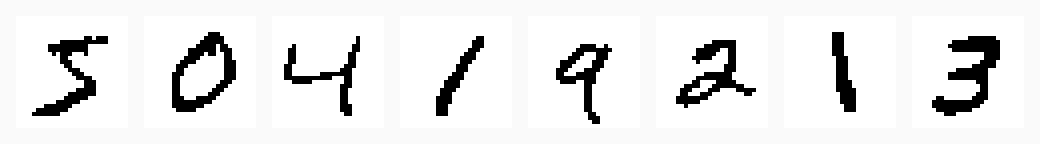

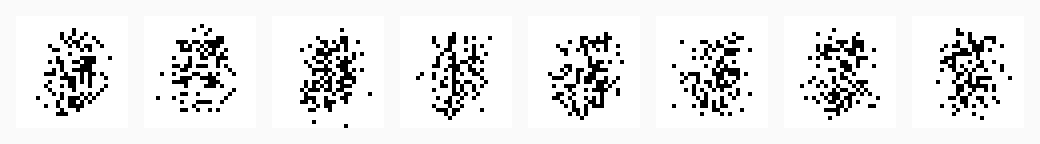

In [11]:
display(Image(filename=str(ROOT/'figures/pedagogy-replay.png'), width=850))
display(Image(filename=str(ROOT/'figures/pedagogy-independent.png'), width=850))


## A small KL detour

KL(q || p) averages log(q/p) under q. Individual contributions may be negative; the total is nonnegative. Reversing the arguments changes both the log ratio and the averaging weights.


In [12]:
q = np.array([.8, .2]); p = np.array([.5, .5])
contributions = q * np.log(q/p)
print('Contributions:', contributions)
print('KL(q || p):', contributions.sum(), 'nats')
print('KL(p || q):', (p*np.log(p/q)).sum(), 'nats')
assert np.isclose(contributions.sum(), .19274475702175753)


Contributions: [ 0.3760029  -0.18325815]
KL(q || p): 0.19274475702175753 nats
KL(p || q): 0.22314355131420976 nats


## Compute an evidence bound exactly in a finite model

The generative model has three latent states. Hold its parameters fixed while improving q. This lets us compute the evidence and posterior KL gap, quantities generally unavailable exactly in the neural model.


In [13]:
prior = np.array([.2, .5, .3]); likelihood = np.array([.1, .8, .2])
evidence = prior @ likelihood
posterior = prior * likelihood / evidence
for q in [np.array([.4,.3,.3]), np.array([.15,.7,.15]), posterior]:
    elbo = np.sum(q*np.log(prior*likelihood/q))
    gap = np.sum(q*np.log(q/posterior))
    print('q:', q, 'ELBO:', elbo, 'gap:', gap)
    assert np.isclose(np.log(evidence), elbo+gap)


q: [0.4 0.3 0.3] ELBO: -1.5948196614162922 gap: 0.860850486336092
q: [0.15 0.7  0.15] ELBO: -0.8314101144172586 gap: 0.0974409393370584
q: [0.04166667 0.83333333 0.125     ] ELBO: -0.7339691750802002 gap: 0.0


## sample() versus rsample()

PyTorch's ordinary sample does not retain this pathwise autograd connection. A reparameterized draw does. Other gradient estimators exist; stochastic computation is not inherently impossible to differentiate.


In [14]:
mu = torch.tensor(2., requires_grad=True)
std = torch.tensor(.5, requires_grad=True)
dist = torch.distributions.Normal(mu, std)
print('sample requires grad:', dist.sample().requires_grad)
torch.manual_seed(667)
z = dist.rsample()
z.backward()
print('rsample gradients:', mu.grad.item(), std.grad.item())
assert mu.grad.item() == 1.


sample requires grad: False
rsample gradients: 1.0 -0.9787107706069946


## Controlled beta experiment

Three separate 2D VAEs use identical initialization, data order and noise seeds: first 12,000 training images, 12 epochs, Adam 0.001. Reconstruction sums pixel BCE; KL sums latent coordinates; both then average over examples. The same held-out images and prior vectors appear in every panel. This single-seed comparison is distinct from the lecture's original 60,000-image run.

Beta = 0 retains a stochastic encoder. Larger beta does not guarantee semantic axes or disentanglement. Test metrics use one posterior sample per example; the Gaussian KL is analytical.


beta0 test reconstruction: 152.88278198242188 test KL: 42.70679473876953


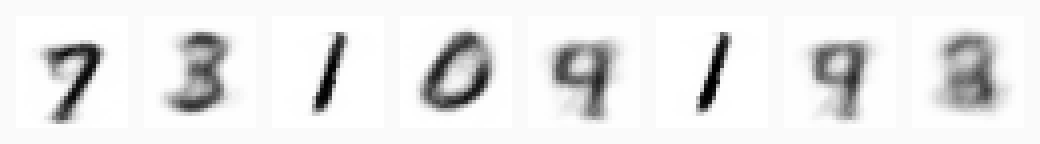

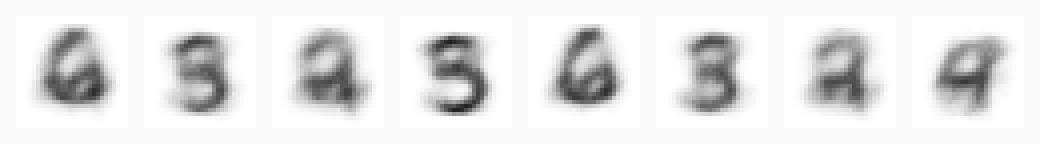

beta1 test reconstruction: 156.21839904785156 test KL: 5.162355422973633


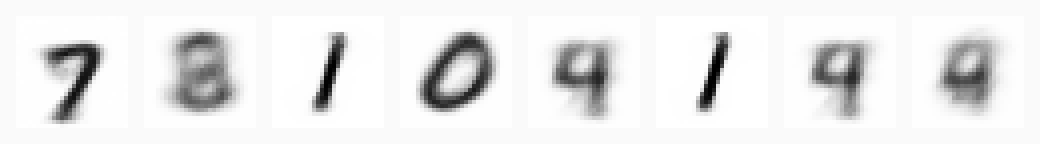

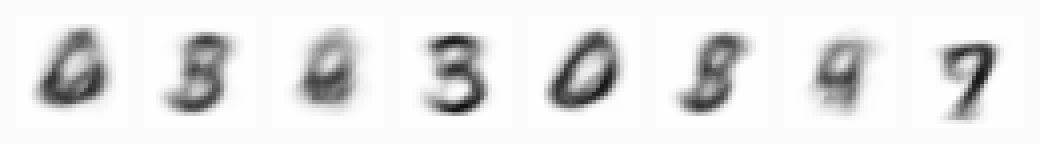

beta4 test reconstruction: 162.81605529785156 test KL: 3.042499303817749


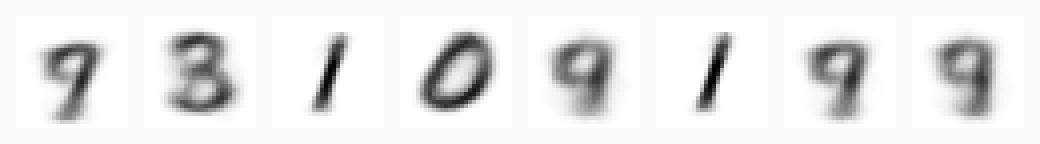

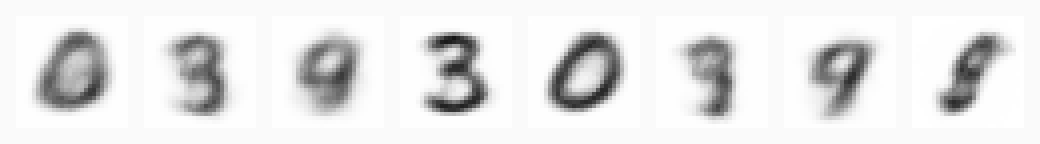

In [15]:
ped = json.loads((ROOT/'metrics/pedagogy.json').read_text())
for row in ped['beta']:
    name = 'beta'+str(int(row['beta']))
    print(name, 'test reconstruction:', row['test_reconstruction_nats'], 'test KL:', row['test_kl_nats'])
    display(Image(filename=str(ROOT/f'figures/pedagogy-{name}-recon.png'), width=850))
    display(Image(filename=str(ROOT/f'figures/pedagogy-{name}-prior.png'), width=850))
RUN_BETA_TRAINING = False
if RUN_BETA_TRAINING:
    subprocess.run([sys.executable, str(ROOT/'experiments/pedagogy_evidence.py')], check=True)


## ELBO: change the averaging distribution, then apply Jensen

Use the exact three-state model to compare `log(E[w])` with `E[log(w)]`. The latter is the bound. Try the true posterior as q: every importance weight then equals the evidence.

[Kingma & Welling](https://arxiv.org/abs/1312.6114) · [Lilian Weng’s VAE explanation](https://lilianweng.github.io/posts/2018-08-12-vae/) · [Nipun’s variational-inference lecture](https://www.youtube.com/watch?v=fQ8D0-tTCBU)


In [16]:
toy = json.loads((ROOT/'results/pedagogy.json').read_text())['toy']
joint = np.array(toy['prior']) * toy['likelihood']
for row in toy['states']:
    q = np.array(row['q'])
    weights = joint/q
    log_average = np.log(q @ weights)
    average_log = q @ np.log(weights)
    print('weights:', weights, 'log E[w]:', log_average, 'E[log w]:', average_log)
    assert average_log <= log_average + 1e-12
    assert np.isclose(average_log, row['elbo'])


weights: [0.05       1.33333333 0.2       ] log E[w]: -0.7339691750802003 E[log w]: -1.5948196614162922
weights: [0.13333333 0.57142857 0.4       ] log E[w]: -0.7339691750802003 E[log w]: -0.8314101144172586
weights: [0.48 0.48 0.48] log E[w]: -0.7339691750802003 E[log w]: -0.7339691750802002


## GAN: Bayes-optimal source classifier and Jensen–Shannon divergence

The class prior is part of the experiment. Start with equal source priors; then change pi. A score of one half at just one outcome does not imply that the two distributions agree everywhere.

[Original GAN paper, Sections 3–4](https://arxiv.org/abs/1406.2661) · [Lilian Weng: From GAN to WGAN](https://lilianweng.github.io/posts/2017-08-20-gan/)


In [17]:
p_data = np.array([.6,.3,.1])
p_g = np.array([.1,.3,.6])
for pi in [.1,.5,.9]:
    d = pi*p_data/(pi*p_data+(1-pi)*p_g)
    print('data-source prior:', pi, 'Bayes source probabilities:', d)
m = (p_data+p_g)/2
js = .5 * (np.sum(p_data*np.log(p_data/m)) + np.sum(p_g*np.log(p_g/m)))
d_star = p_data/(p_data+p_g)
value = p_data @ np.log(d_star) + p_g @ np.log(1-d_star)
print('JS:', js, 'minimax value at optimal D:', value)
assert np.isclose(value, -np.log(4)+2*js)


data-source prior: 0.1 Bayes source probabilities: [0.4        0.1        0.01818182]
data-source prior: 0.5 Bayes source probabilities: [0.85714286 0.5        0.14285714]
data-source prior: 0.9 Bayes source probabilities: [0.98181818 0.9        0.6       ]
JS: 0.19812160359007547 minimax value at optimal D: -0.9900511539397397


## Why the non-saturating generator loss?

Differentiate with respect to the discriminator logit. The full generator gradient also passes through the discriminator input and generator parameters. These derivatives alone do not guarantee stable training.


In [18]:
a = torch.tensor(-4., requires_grad=True)
minimax = torch.nn.functional.logsigmoid(-a)
non_saturating = -torch.nn.functional.logsigmoid(a)
g_minimax = torch.autograd.grad(minimax, a, retain_graph=True)[0]
g_non_saturating = torch.autograd.grad(non_saturating, a)[0]
d = torch.sigmoid(a)
print('D:', d.item(), 'minimax derivative:', g_minimax.item(), 'non-saturating derivative:', g_non_saturating.item())
assert torch.allclose(g_minimax, -d)
assert torch.allclose(g_non_saturating, d-1)


D: 0.01798621006309986 minimax derivative: -0.01798621006309986 non-saturating derivative: -0.9820137619972229


## Continue with the course resources

- [Jaan Altosaar’s probabilistic VAE tutorial](https://jaan.io/what-is-variational-autoencoder-vae-tutorial)
- [Nipun’s VAE lecture](https://www.youtube.com/watch?v=bo8wceOS6C0)
- [Nipun’s PML notebook](https://github.com/nipunbatra/pml-teaching/blob/master/notebooks/vae.ipynb)
- [MIT 6.S191 generative-model lecture](https://www.youtube.com/watch?v=R8V8CbuxryI)
- [All lecture resources](../resources.html)
